# 3. Apprentissage d'un CNN sur le dataset MNIST
*Objectif: Apprendre à classifier les images de chiffres manuscripts (0 à 9) à l'aide d'un réseau de neurones convolutif (CNN)*

In [18]:
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report


In [19]:
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.mnist.load_data()

In [20]:
plt.figure(figsize=(10,8))
for digit in range(10):
    idx  = np.where(y_train == digit)[0][:0]
    for i, j in enumerate(idx):
        plt.subplot(10,3, digit*3 +i + 1)
        plt.imshow(X_train_raw[j], cmap='gray')
        
        plt.axis('off')
plt.suptitle("Images orginales (0-255)")
plt.show()

<Figure size 1000x800 with 0 Axes>

Normalisation: les pixels passent de 0-255 à 0-1

In [21]:
X_train = X_train_raw.astype("float32")/255.0
X_test = X_test_raw.astype("float32") /255.0

Ajout du canal: (N,28,,28) devient(N,28,28,1)

In [22]:
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

print("Formes finales : ", X_train.shape, X_test.shape)

Formes finales :  (60000, 28, 28, 1) (10000, 28, 28, 1)


In [23]:
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])


In [27]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [28]:
#model
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

```La Validatio est prélevée dans le train (validation_split): le jeu de test reste inconnu jusqu'à l'évaluation finale```

In [29]:
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.9173 - loss: 0.2643 - val_accuracy: 0.9822 - val_loss: 0.0527
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9766 - loss: 0.0787 - val_accuracy: 0.9892 - val_loss: 0.0379
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9831 - loss: 0.0556 - val_accuracy: 0.9908 - val_loss: 0.0337
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9864 - loss: 0.0457 - val_accuracy: 0.9908 - val_loss: 0.0345
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9889 - loss: 0.0367 - val_accuracy: 0.9903 - val_loss: 0.0364


In [30]:
loss, acc=model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test: {acc*100:.2f}")

313/313 - 1s - 4ms/step - accuracy: 0.9898 - loss: 0.0298

Précision sur le test: 98.98


In [31]:
y_pred = np.argmax(model.predict(X_test), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


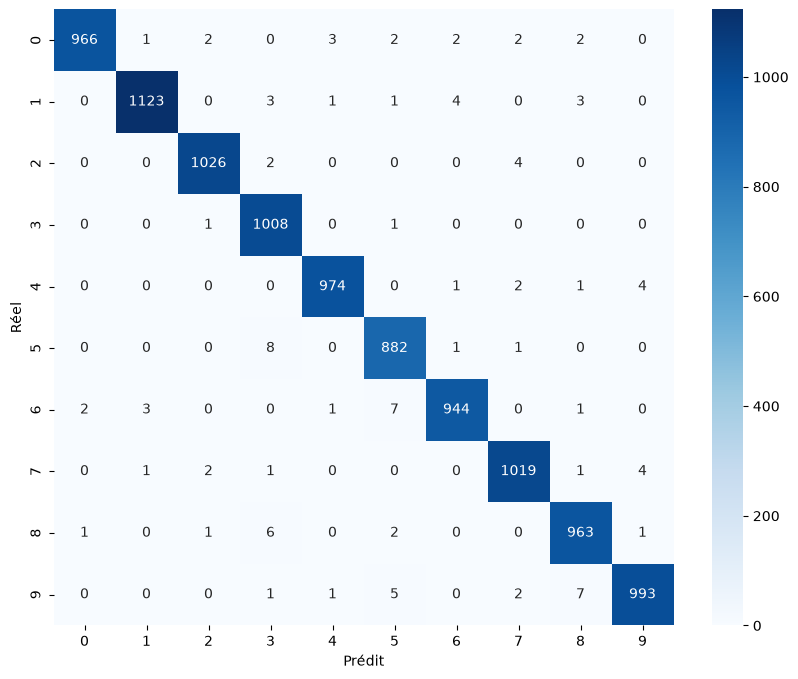

In [33]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,8))
sn.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

In [34]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       980
           1       1.00      0.99      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.98      1.00      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.98       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.98      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

